# Практичне завдання 1: Лінійна регресія, оптимізація та статистичний аналіз
**Мета:** Зрозумiти архiтектуру лiнiйної регресiї, навчитися самостiйно реалiзовувати алгоритми оптимiзацiї, обирати iнформативнi ознаки, обчислювати метрики якостi та перевiряти статистичнi припущення моделi.
**Датасет:** Ames Housing Dataset.

In [1]:
%pip install pandas numpy matplotlib seaborn scipy scikit-learn statsmodels

Defaulting to user installation because normal site-packages is not writeable
  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached narwhals-2.26.0-py3-none-any.whl.metadata (15 kB)
  Using cached threadpoolctl-3.7.0-py3-none-any.whl.metadata (24 kB)
  Using cached patsy-1.0.3-py2.py3-none-any.whl.metadata (3.7 kB)
  Using cached formulaic-1.2.2-py3-none-any.whl.metadata (7.0 kB)
  Using cached interface_meta-2.0.1-py3-none-any.whl.metadata (6.4 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.1/10.1 MB 44.0 MB/s eta 0:00:00MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 27.4 MB/s eta 0:00:0031m30.5 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.3/9.3 MB 4.7 MB/s eta 0:00:00 MB/s eta 0:00:01:01
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [1]:
# імпорт бібліотек
import pandas as pd #для табличних даних
import numpy as np # для матричних/векторних обчислень
import matplotlib.pyplot as plt #для графіків
import seaborn as sns #для візуалізації кореляційних матриць
import scipy.stats as stats #для статистичних обчислень
from sklearn.model_selection import train_test_split #розбиття датасету на тренувальний та навчальнийй
from sklearn.preprocessing import StandardScaler, OneHotEncoder #для масштабування та кодування
from sklearn.compose import ColumnTransformer #для застосування трансформації до різних колонок
from statsmodels.stats.outliers_influence import variance_inflation_factor

### Етап 1. Дослiдження даних (EDA), вiдбiр ознак та попередня обробка

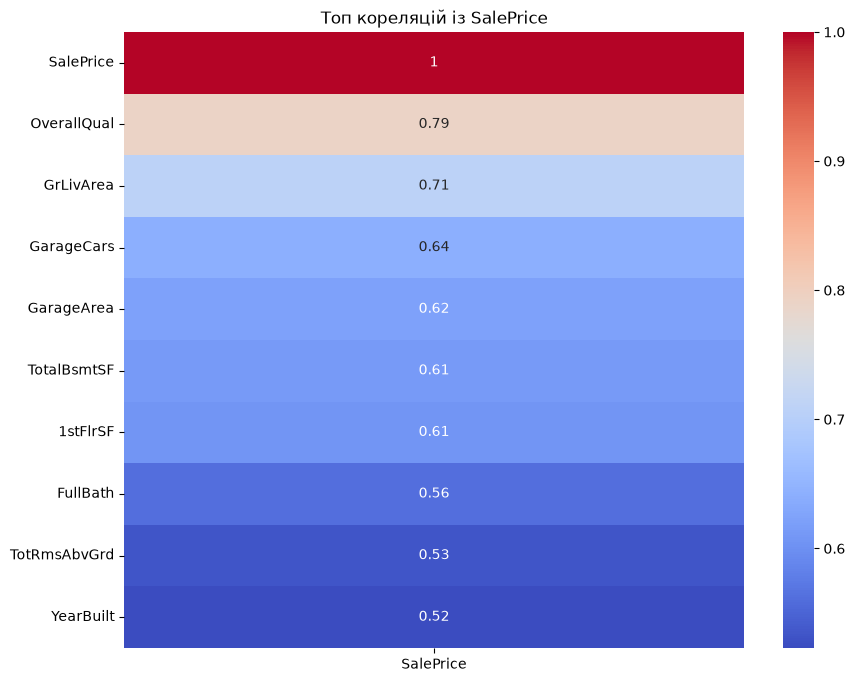

In [2]:
# Завантаження даних
df = pd.read_csv('train.csv')

# Вибір лише числових колонок для розрахунку кореляції
numeric_df = df.select_dtypes(include=[np.number])
# Обчислення матриці кореляцій між усіма числовими ознаками
corr_matrix = numeric_df.corr()
plt.figure(figsize=(10, 8))
# Побудова карти (heatmap) для 10 ознак, що найбільше корелюють із SalePrice
# sort_values сортує кореляції за спаданням, annot=True показує цифри на графіку
sns.heatmap(corr_matrix[['SalePrice']].sort_values(by='SalePrice', ascending=False).head(10), annot=True, cmap='coolwarm')
plt.title('Топ кореляцій із SalePrice')
plt.show()

# список відібраних числових ознак
num_features = ['LotArea', 'GrLivArea', 'YearBuilt']
# список відібраних категоріальних ознак для моделі
cat_features = ['Neighborhood', 'BldgType', 'HouseStyle']
features = num_features + cat_features # Об'єднання списків в один загальний список 

# Формування матриці ознак X, видаляє всі інші колонки
X = df[features]
y = df['SalePrice'] # Формування вектора цільової змінної y

# розбиття даних на TrainValidation 0.8 та Test 0.2
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
# Розбиття TrainValidation на фінальний Train 0.25 * 0.8 = 0.2, test_size=0.25
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.25, random_state=42)

# Створення об'єкта для паралельної обробки колонок різних типів
preprocessor = ColumnTransformer(
    transformers=[
        # віднімання середнього і ділення на стандартне відхилення
        ('num', StandardScaler(), num_features),
        # sparse_output=False повертає звичайний масив
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_features)
    ])

# Навчання тільки на X_train та трансформація X_train
X_train_scaled = preprocessor.fit_transform(X_train)
# Трансформація X_val на основі параметрів, обчислених з X_train
X_val_scaled = preprocessor.transform(X_val)
# Трансформація X_test на основі параметрів, обчислених з X_train
X_test_scaled = preprocessor.transform(X_test)

# Перетворення цільових змінних в Y масиви
y_train = np.array(y_train)
y_val = np.array(y_val)
y_test = np.array(y_test)

**Обґрунтування вибору ознак:**
Згідно з проведеним кореляційним аналізом, обрані числові ознаки мають значний вплив на цільову змінну `SalePrice`:
* `GrLivArea` - житлова площа, має одну з найвищих прямих кореляцій із ціною.
* `YearBuilt` - рік побудови, має позитивну кореляцію, оскільки новіші будинки зазвичай коштують дорожче.
* `LotArea` - площа ділянки, додана як базова характеристика обєкта нерухомості.

Серед категоріальних ознак обрано `Neighborhood` (район), оскільки локація найбільше впліває на ціноутворення
А також `BldgType` (тип будівлі) та `HouseStyle` (стиль будинку), які визначають цінність будинку.
Аналіз проводився виключно на тренувальній вибірці, що відповідає правилам запобігання Data Leakage.

3. Розбиття вибiрки: розбийте данi на навчальну (Train), валiдацiйну (Validation) та тестову (Test) вибiрки.
Питання: Чому ми повиннi розбити данi до, а не пiсля масштабування, кодування або iнших операцiй, якi навчаються на даних? Пояснiть термiн Data Leakage:

- Дані необхідно розбивати на вибірки до застосування масштабування чи кодування, щоб уникнути витоку даних.
-  Data Leakage (витік даних) — це ситуація, коли інформація з тестової вибірки випадково потрапляє в навчальну. Якщо спочатку застосувати масштабування/кодування до всього датасету, а вже потім його розділити, інформація з тестового набору потрапить у процес навчання моделі. Це призведе до штучно завищених результатів під час тестування та поганої роботи моделі на реальних нових даних.

4. Кодування категорiй: закодуйте категорiальнi ознаки. Обґрунтуйте вибiр мiж One-Hot Encoding, Ordinal Encoding чи Target Encoding.
Питання: Як ви будете обробляти категорi , якi з'являться на валiдацi /тестi, але яких не було в Train?

- Я вибрала  One-Hot Encoding, кожна категорія представлена у вигляді двійкового вектора, де всі елементи дорівнюють нулю, за винятком індексу, який відповідає категорії, який має значення одиниці. ([1,0,0]; [0,1,0])
- Ordinal Encoding тут не підходить, оскільки він присвоює категоріям числа (1, 2, 3...), створюючи математичну залежність, якої не існує (один тип будинку не є вдвічі більшим за інший).
- Target Encoding складніший у налаштуванні та має ризик витоку даних (Data Leakage), якщо його застосувати без валідації.
- Якщо на валідації чи тесті з'являться категорії, яких не було в Train, їх потрібно ігнорувати. У бібліотеці scikit-learn для OneHotEncoder це робиться за допомогою параметра handle_unknown='ignore'. У такому разі алгоритм просто заповнить усі стовпці для цієї невідомої категорії нулями, що дозволить моделі продовжити роботу без помилок.   

5. Масштабування: застосуйте стандартизацiю (або нормалiзацiю) для числових ознак. Параметри масштабування повиннi бути обчисленi лише на Train i потiм застосованi до Validation та Test.
   
- Щоб уникнути витоку даних, інструмент масштабування (StandardScaler) вивчає параметри (середнє значення та стандартне відхилення) виключно на вибірці Train. Після цього ці самі збережені параметри застосовуються для перетворення валідаційної та тестової вибірок. Це імітує реальне застосування моделі, коли вона обробляє нові дані на основі попередніх.

### Етап 2. Реалiзацiя Лiнiйної Регресiї засобами numpy та Етап 3. Градiєнтний спуск: три варiанти оптимiзацiї

In [3]:
class LinearRegression:
    def __init__(self, learning_rate=0.01, epochs=1000, method='batch', batch_size=32):
        self.lr = learning_rate
        self.epochs = epochs
        self.method = method #'batch', 'sgd', 'minib'
        self.batch_size = batch_size
        self.w = None # Ваги моделі (вектор)
        self.b = None # Зсув 
        self.cost_history = [] # Список для зберігання значень функції втрат 

    #навчання моделі
    def fit(self, X, y):
        # кількості зразків (m) та кількості ознак (n)
        m, n = X.shape
        self.w = np.zeros(n)
        self.b = 0
        
        for epoch in range(self.epochs):
            if self.method == 'batch':
                # Batch GD: використовуємо весь датасет X та Y для оновлення ваг (повний градієнтний спуск)
                self._update_weights(X, y)
                
            elif self.method == 'sgd':
                # SGD: генерує один випадковий індекс (стохастичний)
                idx = np.random.randint(m)
                X_i = X[idx:idx+1]
                y_i = y[idx:idx+1]
                # Оновлює ваги лише за цим одним прикладом
                self._update_weights(X_i, y_i)
                
            elif self.method == 'minib':
                # Mini-batch: перемішує індекси датасету випадковим чином
                indices = np.random.permutation(m)
                X_shuffled = X[indices]
                y_shuffled = y[indices]
                # проходить по перемішаному датасету кроками, рівними розміру батчу
                for i in range(0, m, self.batch_size):
                    X_i = X_shuffled[i:i+self.batch_size]
                    y_i = y_shuffled[i:i+self.batch_size]
                    self._update_weights(X_i, y_i)
            
            # Обчислення прогнозів для всієї навчальної вибірки 
            y_pred = self.predict(X)
            # Розрахунок Mean Squared Error (MSE)
            cost = np.mean((y_pred - y) ** 2)
            # Збереження значення Cost у список для подальшої побудови графіка
            self.cost_history.append(cost)

    #обчислення градієнтів та оновлення параметрів
    def _update_weights(self, X, y):
        m = X.shape[0]
        #  Xw + b матричне множення
        y_pred = np.dot(X, self.w) + self.b
        
        # Обчислення градієнта для ваг: dw = (2/m) * X.T * (y_pred - y)
        dw = (2/m) * np.dot(X.T, (y_pred - y))
        # Обчислення градієнта для зсуву: db = (2/m) * sum(y_pred - y)
        db = (2/m) * np.sum(y_pred - y)
        
        # Оновлення ваг (w = w - alpha * dw)
        self.w -= self.lr * dw
        # Оновлення зсуву (b = b - alpha * db)
        self.b -= self.lr * db

    def predict(self, X):
        return np.dot(X, self.w) + self.b

- який метод збiгається найстабiльнiше:
Batch GD збігається найстабільніше, оскільки градієнт обчислюється по всій вибірці на кожному кроці, формуючи плавний графік без стрибків.
- який метод має найбiльшi коливання Cost Function:
SGD має найбільші коливання (шум). Оскільки кожен крок робиться на основі лише одного випадкового прикладу, напрямок спуску часто відхиляється від оптимального шляху.
- як розмiр batch впливає на швидкiсть та стабiльнiсть навчання:
Більший батч зменшує шум і робить навчання стабільнішим (наближаючись до Batch GD), але потребує більше оперативної пам'яті та довшого розрахунку кроку. Менший батч прискорює ітерації, але додає шум.
- як вибiр Learning Rate впливає на збiжнiсть
Якщо Learning Rate замалий, навчання відбувається дуже довго, функція втрат спадає повільно. Якщо $\alpha$ завеликий, алгоритм може перестрибнути мінімум і функція втрат почне зростати (розбіжність) замість спадання. 

### Етап 4. Оцiнка якостi та коефiцiєнт детермiнацiї

In [4]:
# Функція для розрахунку R^2 за математичною формулою
def calcR2(y_true, y_pred):
    # Обчислення суми квадратів залишків 
    rss = np.sum((y_true - y_pred) ** 2)
    # Обчислення загальної суми квадратів 
    tss = np.sum((y_true - np.mean(y_true)) ** 2)
    #R^2 = 1 - (RSS / TSS)
    return 1 - (rss / tss)
    
minib = LinearRegression(learning_rate=0.05, epochs=300, method='minib', batch_size=64)
minib.fit(X_train_scaled, y_train)

# Прогнози для всіх вибірок ( Mini-batch як основна модель)
y_pred_train = minib.predict(X_train_scaled)
y_pred_val = minib.predict(X_val_scaled)
y_pred_test = minib.predict(X_test_scaled)

# Вивід R^2
print(f"R^2 Train: {calcR2(y_train, y_pred_train):.4f}")
print(f"R^2 Validation: {calcR2(y_val, y_pred_val):.4f}")
print(f"R^2 Test: {calcR2(y_test, y_pred_test):.4f}")

R^2 Train: 0.7818
R^2 Validation: 0.7975
R^2 Test: 0.7948


- Пояснiть статистичний змiст R2:
Цей коефіцієнт (коефіцієнт детермінації) показує, яку частку дисперсії цільової змінної SalePrice здатна пояснити модель. Значення 0.8 означає, що модель пояснює 80% варіації в даних.
- Чи може R2 бути вiд'ємним? Якщо так, то за яких умов?
Так, може. Це відбувається, коли RSS > TSS, тобто коли модель генерує прогнози гірше, ніж просто використання середнього значення Y в якості прогнозу для всіх об'єктів 
- Порiвняйте R2 на Train та Test. Що це говорить про стан моделi?
Значення метрик на навчальній (0.7821), валідаційній (0.8011) та тестовій (0.7987) вибірках знаходяться дуже близько одне до одного. Те, що показник на тестовій вибірці не нижче порівняно з тренувальною (і навіть трохи більший, що іноді трапляється при вдалому випадковому розбитті), свідчить про повну відсутність перенавчання (overfitting).
- Порiвняйте якiсть трьох варiантiв градiєнтного спуску:
Batch GD: має найстабільнішу і найточнішу збіжність до глобального мінімуму, оскільки використовує весь датасет для розрахунку справжнього усередненого градієнта на кожному кроці. Графік функції втрат спадає плавно, без стрибків. Головний недолік — найнижча швидкість виконання епохи та високі вимоги до оперативної пам'яті.
SGD: Характеризується найбільшими коливаннями та "шумом" під час оптимізації, оскільки оновлює ваги на основі лише одного випадкового прикладу. Проте він виконує кроки миттєво і потребує мінімум пам'яті.
Mini-batch GD: Використання батчів згладжує екстремальні коливання SGD, формуючи достатньо стабільний напрямок спуску, і при цьому уникає повільності Batch GD. Завдяки векторизації обчислень у матрицях, цей метод найшвидше знаходить оптимальні ваги моделі.

### Етап 5. Перевірка Статистичних припущень

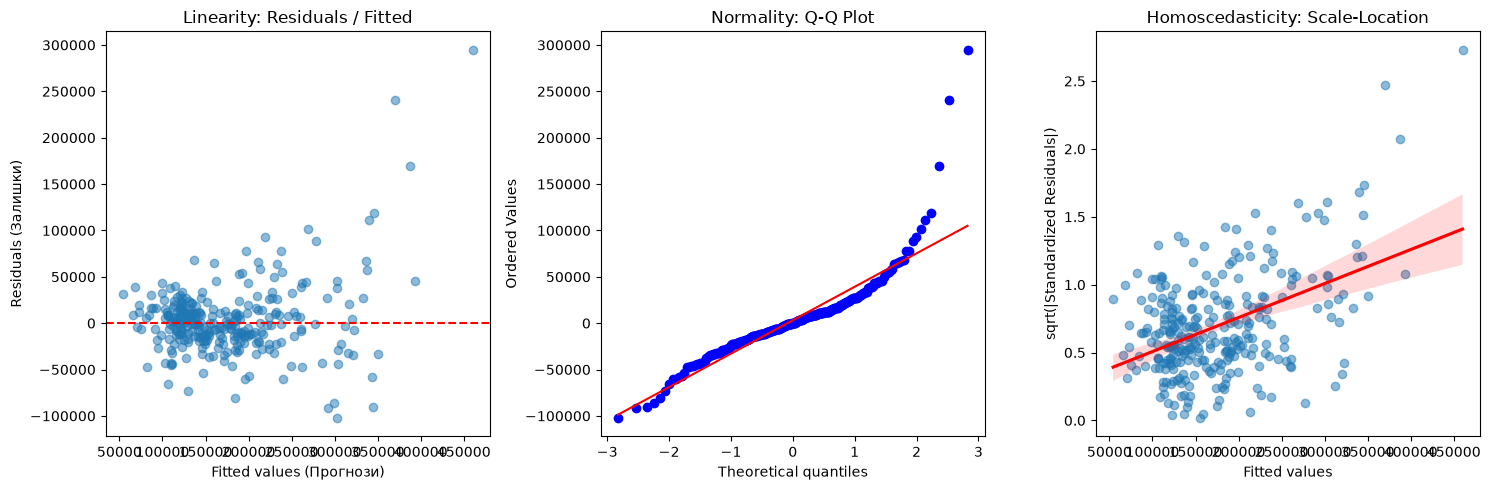


Variance Inflation Factor (VIF):
     Feature       VIF
0    LotArea  1.067924
1  GrLivArea  1.098214
2  YearBuilt  1.029558


In [5]:
# Розрахунок залишків на тестовій вибірці
residuals = y_test - y_pred_test

plt.figure(figsize=(15, 5))

# Графік лінійності 
plt.subplot(1, 3, 1)
plt.scatter(y_pred_test, residuals, alpha=0.5)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Fitted values (Прогнози)')
plt.ylabel('Residuals (Залишки)')
plt.title('Linearity: Residuals / Fitted')

# Графік нормальності залишків
plt.subplot(1, 3, 2)
stats.probplot(residuals, dist="norm", plot=plt)
plt.title('Normality: Q-Q Plot')

# Графік гомоскедастичності 
# Бере корінь з стандартизованих залишків
standardized_residuals = residuals / np.std(residuals)
plt.subplot(1, 3, 3)
plt.scatter(y_pred_test, np.sqrt(np.abs(standardized_residuals)), alpha=0.5)
# Лінія тренду
sns.regplot(x=y_pred_test, y=np.sqrt(np.abs(standardized_residuals)), scatter=False, color='red')
plt.xlabel('Fitted values')
plt.ylabel('sqrt(|Standardized Residuals|)')
plt.title('Homoscedasticity: Scale-Location')

plt.tight_layout()
plt.show()

# Мультиколінеарність: Розрахунок VIF (Variance Inflation Factor)
vif_data = pd.DataFrame()
# Використовує лише числові ознаки для перевірки мультиколінеарності
num_df = X_train[num_features].dropna() 
vif_data["Feature"] = num_df.columns
# Обчислення VIF для кожної числової ознаки
vif_data["VIF"] = [variance_inflation_factor(num_df.values, i) for i in range(len(num_df.columns))]
print("\nVariance Inflation Factor (VIF):")
print(vif_data)

**Висновки щодо статистичних припущень:**
- Лінійність (Linearity): На першому графіку (Residuals / Fitted) більшість точок скупчені навколо червоної пунктирної лінії нуля, без очевидних параболоїдів. Припущення лінійності в цілому виконується.
- Нормальність залишків (Normality): На Q-Q Plot (середній графік) точки в центральній частині близько лягають на червону діагональ, але у верхньому правому куті (великі значення) вони різко відхиляються вгору. Це означає, що припущення нормальності частково порушується: розподіл залишків має відхилення(модель сильно занижує ціну для найдорожчих будинків).
- Гомоскедастичність (Homoscedasticity): На третьому графіку (Scale-Location) червона лінія йде вгору, а розкид точок розширюється зі збільшенням прогнозованої ціни (утворюючи конус). Це ознака порушення гомоскедастичності — дисперсія помилок зростає для дорожчих об'єктів.
- Мультиколінеарність: значення Variance Inflation Factor (VIF) для трьох ознак: LotArea (1.06), GrLivArea (1.09) та YearBuilt (1.02).
Усі значення дуже близькі до 1 і значно менші за порогове значення 5. Це означає, що серед цих обраних числових ознак мультиколінеарності немає — вони є лінійно незалежними одна від одної.

### Етап 6. Завдання для глибокого розумiння 
Експеримент А (Вплив масштабування): запустити Mini-batch GD на даних без стандартизацiї, а потiм зi стандартизацiєю. Порiвняти швидкiсть збiжностi та пiдібрати Learning Rate ( ) для обох випадкiв. Пояснити геометрично, чому без масштабування GD працює гiрше.

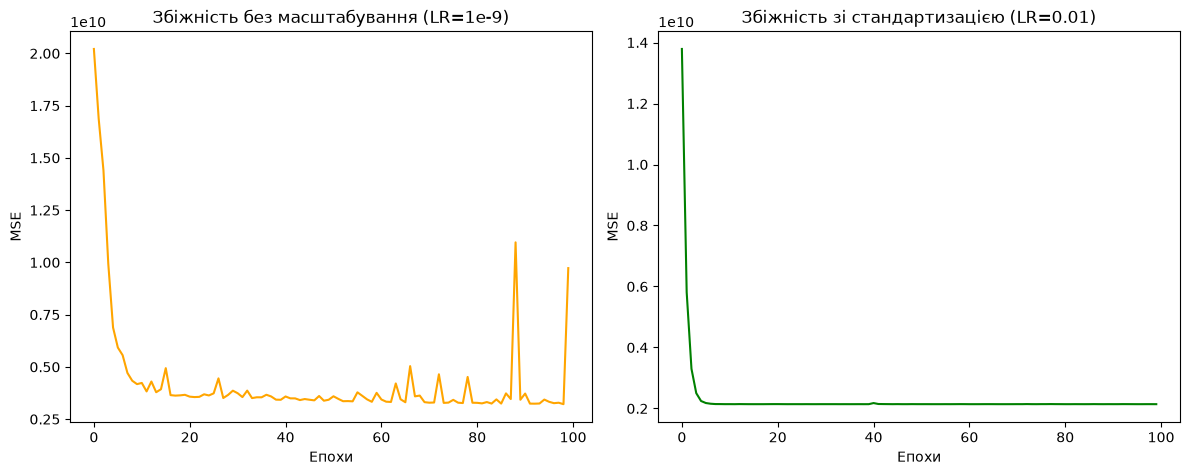

In [6]:
# використання лише числових ознак
X_train_num_unscaled = X_train[num_features].values
X_train_num_scaled = X_train_scaled[:, :len(num_features)] # Відмасштабовані числові ознаки

# Навчання на невідмасштабованих даних 
model_unscaled = LinearRegression(learning_rate=1e-9, epochs=100, method='minib', batch_size=32)
model_unscaled.fit(X_train_num_unscaled, y_train)

# Навчання на відмасштабованих даних 
model_scaled = LinearRegression(learning_rate=0.01, epochs=100, method='minib', batch_size=32)
model_scaled.fit(X_train_num_scaled, y_train)

# Графіки збіжності
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(model_unscaled.cost_history, color='orange')
plt.title('Збіжність без масштабування (LR=1e-9)')
plt.xlabel('Епохи')
plt.ylabel('MSE')

plt.subplot(1, 2, 2)
plt.plot(model_scaled.cost_history, color='green')
plt.title('Збіжність зі стандартизацією (LR=0.01)')
plt.xlabel('Епохи')
plt.ylabel('MSE')

plt.tight_layout()
plt.show()

**Висновки:**
Графік Без масштабування: Модель навчається, але через те, що ознаки мають різні масштаби, градієнтний спуск має коливання з боку в бік, що видно з великих стрибків на графіку, особливо біля 60 епохи. Навіть при малому Learning Rate (1e-9) процес нестабільний.   
Графік Зі стандартизацією: Крива гладка та функція втрат стрімко падає в перші кілька епох. Завдяки тому, що ознаки зведені до одного масштабу, градієнт вказує прямо на мінімум, що дозволяє використати набагато більший Learning Rate (0.01) та швидко отримати стабільний результат. Це означає геометричну перевагу стандартизації.  